# 1. Introdução: o que este caderno valida

Os cadernos 1 e 2 **descrevem** os dados e **constroem** o modelo. Este caderno 3 faz a pergunta seguinte: *as afirmações que fizemos resistem a um teste estatístico?* Ele não treina nada novo para a produção; usa a mesma base final, o mesmo código de `src/` e a mesma divisão temporal (treino antes de 2025, teste final de 2025 em diante).

**Como ler um teste de hipótese** (ideias do capítulo de testes de hipóteses do EUPATI, https://learning.eupati.eu/mod/book/view.php?id=362&chapterid=387&lang=pt):

| Conceito | Neste projeto |
|---|---|
| **Hipótese nula (H0)** | "Não há efeito": por exemplo, o modelo não separa perdidos de concluídos melhor do que o acaso (AUC = 0,5). |
| **Hipótese alternativa (H1)** | O que queremos sustentar: o modelo separa melhor do que o acaso. |
| **Raciocínio indireto** | Não provamos H1 diretamente; tentamos derrubar H0. Se os dados seriam muito improváveis sob H0, rejeitamos H0. |
| **Valor p** | Probabilidade de ver um resultado tão extremo quanto o observado **se H0 fosse verdade**. Não é a probabilidade de a hipótese estar certa. |
| **Nível de significância (α = 0,05)** | Aceitamos errar (rejeitar H0 verdadeira) em até 5% dos casos: **erro tipo I**. |
| **Erro tipo II** | Não rejeitar H0 quando existe efeito (falta de poder). "Não rejeitar" **não prova** que H0 é verdade. |
| **Intervalo de confiança (IC 95%)** | Faixa de valores plausíveis para a medida (AUC, precisão...). Mostra o tamanho do efeito, que o valor p sozinho não mostra. |

**Duas precauções próprias de dados de onboarding.**
1. Onboardings do mesmo cliente se parecem. Tratá-los como independentes deixaria os intervalos estreitos demais. Por isso os intervalos e valores p do modelo usam **bootstrap por cliente**: sorteamos clientes inteiros, com reposição, 2.000 vezes.
2. Vários testes de uma vez aumentam o risco de um falso positivo. Aplicamos a **correção de Holm** ao conjunto de testes em que o resultado esperado é rejeitar H0.

Todo o aleatório tem semente fixa (0) e os resultados são conferidos com `assert`.

# 2. Mapa: suposição do projeto, hipótese e teste

| # | Suposição que fizemos | H0 (nada acontece) | Teste |
|---|---|---|---|
| H1 | O modelo separa perdidos de concluídos | AUC = 0,5 | Mann-Whitney (um lado) e bootstrap por cliente |
| H2 | O modelo vale mais do que só olhar o histórico do cliente | AUC modelo = AUC do histórico | Bootstrap pareado por cliente |
| H3 | Os eventos dos primeiros dias acrescentam informação ao dia 0 | AUC com eventos = AUC só do dia 0 | Bootstrap pareado por cliente |
| H4 | Quanto mais tarde o ponto de checagem, melhor o modelo | AUC dia 14 = AUC dia 3 | Bootstrap conjunto por cliente |
| H5 | O risco calibrado "35%" significa cerca de 35 em 100 | Risco previsto = proporção observada | Hosmer-Lemeshow (10 grupos) |
| H6 | A lista de risco >= 35% e os 20% de maior risco concentram perdas | Taxa de perda da lista = taxa base | Teste binomial (um lado), IC de Wilson |
| H7 | O desempenho se mantém ao longo do tempo | AUC do primeiro = AUC do último trimestre do teste | Bootstrap por cliente |
| H8 | Os sinais que usamos (login, contrato assinado, histórico, país) e o vazamento dos campos preenchidos são reais | Sem associação com a perda | Qui-quadrado, Mann-Whitney, razão de chances |
| H9 | O resultado não vem de vazamento nem de erro no código | AUC com rótulos embaralhados = 0,5 | Teste de permutação dos rótulos |
| H10 | As "razões" do alerta fazem sentido (corrigir o sinal reduz o risco) | Risco não muda ao corrigir | Wilcoxon pareado (um lado) |

**Três grupos de testes.** Em H1 a H4, H6, H8 e H10 o resultado esperado é *rejeitar* H0 (há efeito): aplicamos Holm. Em H5 e H7 o resultado esperado é *não rejeitar* (calibrado, estável): rejeitar H0 seria o mau resultado, então **não** corrigimos (a decisão sem correção é a mais exigente). H9 (permutação com 20 sorteios) é uma **verificação de sanidade**: seu menor valor p possível é 1/21, então a decisão é "o AUC real está acima de todas as permutações", sem correção.

# 3. Preparação: dados, re-treino honesto e como usar os modelos salvos

In [1]:
from pathlib import Path
import sys, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()                 # pasta submission/ (os notebooks ficam em submission/notebooks)
INPUT, FINAL, MODELS, REPORTS = ROOT / "data" / "input", ROOT / "data" / "final", ROOT / "models", ROOT / "reports"
sys.path.insert(0, str(ROOT / "src"))       # features.py, model_utils.py, role_features.py (copias do projeto)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("pasta do pacote:", ROOT)

pasta do pacote: /Users/filipesilva/Documents/datascience/onboarding_early_warning/submission


In [2]:
from scipy.stats import rankdata, mannwhitneyu, binomtest, chi2, chi2_contingency, fisher_exact, wilcoxon
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score
import joblib, time
import features as FE
import model_utils as MU

T0 = time.time()
SEEDS, ALPHA, B_REP, CK = (0, 1, 2), 0.05, 2000, (3, 7, 14)
df = pd.read_csv(FINAL / "onboarding_final_dataset.csv", low_memory=False, parse_dates=["created_at"])
print("base final:", df.shape, "| perdidos:", int(df.y_lost.sum()), f"({df.y_lost.mean():.1%})")

def populacao(d, dados=None):
    dados = df if dados is None else dados
    m = (dados.days_to_outcome > d) if d else pd.Series(True, index=dados.index)
    if d: m &= dados.created_at >= "2023-01-01"
    x = dados[m]
    return x[x.split_final == "train"].reset_index(drop=True), x[x.split_final == "holdout"].reset_index(drop=True)

def fmtp(v): return "< 1e-300" if v < 1e-300 else f"{v:.1e}"

def auc_fast(y, p):
    r = rankdata(p); n1 = int(y.sum()); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

base final: (19855, 122) | perdidos: 3662 (18.4%)


**Por que re-treinar aqui.** Os arquivos `models/checkpoint_d*.joblib` são os modelos de **produção**: foram treinados com *todos* os onboardings rotulados (até 2026), inclusive os do teste final. Pontuar com eles os onboardings de 2025 em diante seria testar o modelo com dados que ele já viu (otimista). Para validar a promessa "o modelo funciona em onboardings futuros", este caderno treina de novo **somente com dados anteriores a 2025** (mesmo código e mesmas sementes do caderno 2) e pontua o teste final. A calibração usa a mesma validação cruzada por semana do caderno 2.

In [3]:
A = {}
for d in CK:
    cols = FE.feature_list(d); tr, ho = populacao(d)
    b = MU.fit(tr, cols, tr.y_lost, seeds=SEEDS); p = MU.predict_raw(b, ho)
    sem = pd.to_datetime(ho.created_at).dt.to_period("W").astype(str); ordem = {w: i for i, w in enumerate(sorted(sem.unique()))}; metade = (sem.map(ordem) % 2).values
    pc = np.zeros(len(ho))
    for h in (0, 1):                                    # calibração isotônica ajustada na outra metade das semanas
        pc[metade == h] = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p[metade != h], ho.y_lost.values[metade != h]).predict(p[metade == h])
    A[d] = dict(tr=tr, ho=ho, cols=cols, b=b, p=p, pc=pc, y=ho.y_lost.values.astype(int))
assert [round(auc_fast(A[d]["y"], A[d]["p"]), 3) for d in CK] == [0.741, 0.750, 0.777]
assert all(abs(auc_fast(A[d]["y"], A[d]["p"]) - roc_auc_score(A[d]["y"], A[d]["p"])) < 1e-12 for d in CK)
print("OK: AUC do teste final 0,741 / 0,750 / 0,777 (iguais ao caderno 2); populações:", {d: (len(A[d]["tr"]), len(A[d]["ho"])) for d in CK})

OK: AUC do teste final 0,741 / 0,750 / 0,777 (iguais ao caderno 2); populações: {3: (5992, 4519), 7: (5745, 4299), 14: (5298, 3847)}


**Como usar e testar os modelos salvos.** Cada arquivo é um dicionário com o modelo (`bundle`, 3 gradient boostings), a calibração (`iso`), os valores de referência para as razões e os números de avaliação (`eval`). A função abaixo é o uso mínimo: recebe uma linha com os atributos do dia *d* (campos em branco são aceitos) e devolve o risco calibrado.

In [4]:
SAVED = {d: joblib.load(MODELS / f"checkpoint_d{d}.joblib") for d in CK}
def risco(d, linhas):
    """Risco calibrado (0 a 1) de o onboarding ser perdido, dado o ponto de checagem d."""
    B = SAVED[d]; return B["iso"].predict(MU.predict_raw(B["bundle"], linhas))

ex = A[7]["ho"].head(3).copy()
print("modelo salvo, dia 7, três onboardings reais:", np.round(risco(7, ex), 3), "| desfecho real:", ex.y_lost.tolist())
sem_info = ex.head(1).copy()
for c in FE.event_cols(7): sem_info[c] = np.nan                 # nenhum evento conhecido: o modelo aceita campos em branco
print("o mesmo onboarding sem nenhum evento conhecido:", np.round(risco(7, sem_info), 3))

# o que aconteceria se pontuássemos o teste final com o modelo salvo (visto o teste no treino)
tab = pd.DataFrame([{"dia": d, "AUC honesto (treino < 2025)": auc_fast(A[d]["y"], A[d]["p"]), "AUC do modelo salvo no mesmo teste": auc_fast(A[d]["y"], risco(d, A[d]["ho"])),
                     "linhas de treino do modelo salvo": SAVED[d]["trained_rows"], "treinado até": SAVED[d]["trained_until"]} for d in CK]); display(tab.round(3))
assert (tab.iloc[:, 2] > tab.iloc[:, 1]).all()
print("OK: o modelo salvo vai melhor no teste final porque já o viu. Por isso a validação abaixo usa o modelo re-treinado só com dados antes de 2025.")

modelo salvo, dia 7, três onboardings reais: [0.342 0.07  0.342] | desfecho real: [0, 0, 0]
o mesmo onboarding sem nenhum evento conhecido: [0.273]


,dia,AUC honesto (treino < 2025),AUC do modelo salvo no mesmo teste,linhas de treino do modelo salvo,treinado até
0,3,0.741,0.843,10511,2026-06-12
1,7,0.750,0.854,10044,2026-06-12
2,14,0.777,0.874,9145,2026-06-12


OK: o modelo salvo vai melhor no teste final porque já o viu. Por isso a validação abaixo usa o modelo re-treinado só com dados antes de 2025.


# 4. Bootstrap por cliente (base dos intervalos e dos valores p do modelo)

Sorteamos 2.000 vezes os clientes do teste final, com reposição; todas as linhas de um cliente sorteado entram juntas (e repetidas se o cliente for sorteado mais de uma vez). Os mesmos sorteios servem aos três pontos de checagem, o que permite **comparar** pontos (H4) e modelos (H2, H3) no mesmo sorteio (teste pareado). O valor p de um teste de um lado é a fração de sorteios em que a diferença é <= 0 (com o ajuste (1 + contagem) / (2.001)), então o menor valor p possível é 0,0005.

In [5]:
clientes = pd.Index(sorted(set().union(*[set(A[d]["ho"].client_uid) for d in CK]))); nC = len(clientes); rng = np.random.default_rng(0)
PESOS = np.stack([np.bincount(rng.integers(0, nC, nC), minlength=nC) for _ in range(B_REP)]).astype(np.int16)
for d in CK: A[d]["cod"] = clientes.get_indexer(A[d]["ho"].client_uid)
def idx(d, b): return np.repeat(np.arange(len(A[d]["y"])), PESOS[b][A[d]["cod"]])
def boot(d, fn): return np.array([fn(idx(d, b)) for b in range(B_REP)])
def p_um_lado(diff, h0=0.0): return (1 + np.sum(diff <= h0)) / (len(diff) + 1)
def p_dois_lados(diff): return min(1.0, 2 * min((1 + np.sum(diff <= 0)) / (len(diff) + 1), (1 + np.sum(diff >= 0)) / (len(diff) + 1)))
def ic(x): return np.percentile(x, [2.5, 97.5])

RES = []   # (id, família, hipótese, teste, medida, p, leitura)
def reg(i, fam, hip, teste, medida, p, nota=""): RES.append(dict(id=i, familia=fam, hipotese=hip, teste=teste, medida=medida, p=p, nota=nota))
print(f"{nC} clientes distintos no teste final; {B_REP} sorteios; tempo até aqui: {time.time() - T0:.0f}s")

1046 clientes distintos no teste final; 2000 sorteios; tempo até aqui: 2s


# 5. H1: o modelo separa perdidos de concluídos?

**H0:** AUC = 0,5 (o risco previsto não tem relação com o desfecho). **H1:** AUC > 0,5.
O teste de Mann-Whitney compara os riscos previstos dos perdidos com os dos concluídos; sua estatística U dividida por (n1 · n0) é exatamente o AUC. O bootstrap por cliente dá o IC e um valor p que respeita a dependência entre onboardings do mesmo cliente.

,dia,n,perdidos,AUC,IC 95% (por cliente),p Mann-Whitney,p bootstrap por cliente
0,3,4519,917,0.741,0.715 a 0.767,4.1e-113,0.001
1,7,4299,876,0.750,0.724 a 0.777,6.5e-116,0.001
2,14,3847,775,0.776,0.750 a 0.803,8.8e-126,0.001


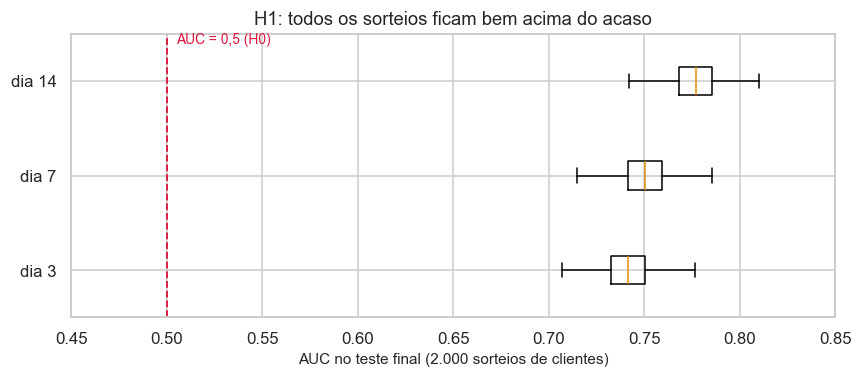

Conclusão H1: rejeitamos H0 nos três pontos de checagem; o AUC fica entre 0,74 e 0,78 e nenhum sorteio chega perto de 0,5.


In [6]:
linhas = []
for d in CK:
    a = A[d]; y, p = a["y"], a["p"]; auc = auc_fast(y, p)
    u = mannwhitneyu(p[y == 1], p[y == 0], alternative="greater"); assert abs(u.statistic / (y.sum() * (len(y) - y.sum())) - auc) < 1e-9
    a["auc_boot"] = boot(d, lambda i: auc_fast(y[i], p[i])); lo, hi = ic(a["auc_boot"]); pb = p_um_lado(a["auc_boot"], 0.5)
    linhas.append({"dia": d, "n": len(y), "perdidos": int(y.sum()), "AUC": auc, "IC 95% (por cliente)": f"{lo:.3f} a {hi:.3f}", "p Mann-Whitney": u.pvalue, "p bootstrap por cliente": pb})
    reg(f"H1 dia {d}", "esperado rejeitar", "AUC > 0,5", "bootstrap por cliente", f"AUC {auc:.3f} (IC {lo:.3f} a {hi:.3f})", pb)
t1 = pd.DataFrame(linhas); display(t1.assign(**{"p Mann-Whitney": t1["p Mann-Whitney"].map(fmtp)}).round(4))
assert (t1["AUC"] > 0.7).all() and all(ic(A[d]["auc_boot"])[0] > 0.68 for d in CK) and (t1["p bootstrap por cliente"] < 0.001).all()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot([A[d]["auc_boot"] for d in CK], labels=[f"dia {d}" for d in CK], vert=False, showfliers=False)
ax.axvline(0.5, color="crimson", ls="--", lw=1.2); ax.text(0.505, 3.4, "AUC = 0,5 (H0)", color="crimson", fontsize=9)
ax.set_xlim(0.45, 0.85); ax.set_xlabel("AUC no teste final (2.000 sorteios de clientes)"); ax.set_title("H1: todos os sorteios ficam bem acima do acaso"); plt.tight_layout(); plt.show()
print("Conclusão H1: rejeitamos H0 nos três pontos de checagem; o AUC fica entre 0,74 e 0,78 e nenhum sorteio chega perto de 0,5.")

# 6. H2, H3 e H4: o modelo vale mais que as alternativas simples?

* **H2.** H0: o AUC do modelo é igual ao da regra "olhar só o histórico de perdas do cliente" (`client_prior_lost_rate`). H1: o modelo é melhor.
* **H3.** H0: o modelo com os eventos do onboarding (login, tarefas) tem o mesmo AUC do modelo treinado só com os atributos conhecidos na criação (dia 0). H1: os eventos ajudam.
* **H4.** H0: o AUC do dia 14 é igual ao do dia 3. H1: o dia 14 é melhor. (Os onboardings avaliados em cada dia não são exatamente os mesmos, pois só os abertos entram; por isso o bootstrap sorteia os mesmos clientes nos dois dias.)

Em todos os casos a medida é a **diferença de AUC**, com IC e valor p do bootstrap pareado por cliente.

,dia,teste,comparação,AUC referência,AUC modelo,diferença,IC 95%,p
0,3,H2,modelo - histórico do cliente,0.583,0.741,0.159,0.129 a 0.190,0.001
1,3,H3,modelo completo - modelo só dia 0,0.597,0.741,0.144,0.125 a 0.163,0.001
2,7,H2,modelo - histórico do cliente,0.577,0.750,0.173,0.142 a 0.208,0.001
3,7,H3,modelo completo - modelo só dia 0,0.606,0.750,0.144,0.123 a 0.166,0.001
4,14,H2,modelo - histórico do cliente,0.580,0.776,0.197,0.163 a 0.234,0.001
5,14,H3,modelo completo - modelo só dia 0,0.605,0.776,0.172,0.144 a 0.199,0.001


H4: AUC dia 14 - dia 3 = +0.035 (IC 0.017 a 0.055), p um lado = 0.0010
    (apenas informativo) AUC dia 7 - dia 3 = +0.009 (IC -0.006 a 0.023), p dois lados = 0.251


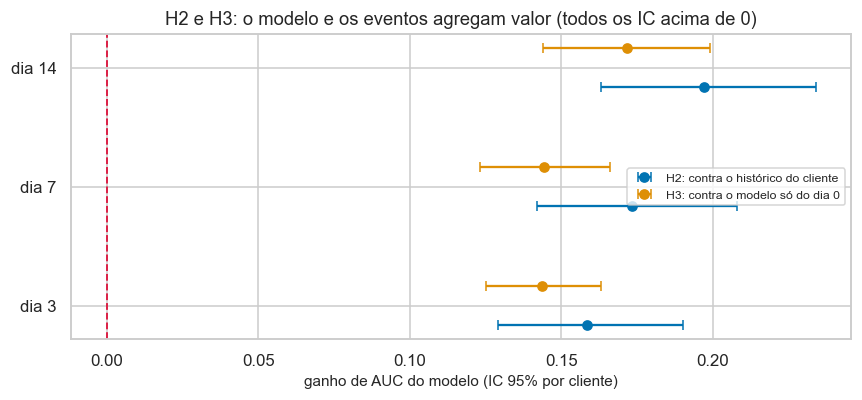

In [7]:
linhas = []
for d in CK:
    a = A[d]; y, p = a["y"], a["p"]; ho, tr = a["ho"], a["tr"]
    base = ho.client_prior_lost_rate.fillna(tr.y_lost.mean()).values
    p0 = MU.predict_raw(MU.fit(tr, FE.DAY0, tr.y_lost, seeds=SEEDS), ho)                   # modelo só com atributos do dia 0
    a["p_base"], a["p_day0"] = base, p0
    for cod, nome, q in (("H2", "modelo - histórico do cliente", base), ("H3", "modelo completo - modelo só dia 0", p0)):
        dif = boot(d, lambda i: auc_fast(y[i], p[i]) - auc_fast(y[i], q[i])); pt = auc_fast(y, p) - auc_fast(y, q); lo, hi = ic(dif); pv = p_um_lado(dif)
        linhas.append({"dia": d, "teste": cod, "comparação": nome, "AUC referência": auc_fast(y, q), "AUC modelo": auc_fast(y, p), "diferença": pt, "IC 95%": f"{lo:.3f} a {hi:.3f}", "p": pv})
        reg(f"{cod} dia {d}", "esperado rejeitar", nome + " > 0", "bootstrap pareado por cliente", f"diferença de AUC {pt:+.3f} (IC {lo:.3f} a {hi:.3f})", pv)
t23 = pd.DataFrame(linhas); display(t23.round(4))

d14 = np.array([auc_fast(A[14]["y"][idx(14, b)], A[14]["p"][idx(14, b)]) - auc_fast(A[3]["y"][idx(3, b)], A[3]["p"][idx(3, b)]) for b in range(B_REP)])
d73 = np.array([auc_fast(A[7]["y"][idx(7, b)], A[7]["p"][idx(7, b)]) - auc_fast(A[3]["y"][idx(3, b)], A[3]["p"][idx(3, b)]) for b in range(B_REP)])
pt14 = auc_fast(A[14]["y"], A[14]["p"]) - auc_fast(A[3]["y"], A[3]["p"]); pt73 = auc_fast(A[7]["y"], A[7]["p"]) - auc_fast(A[3]["y"], A[3]["p"])
print(f"H4: AUC dia 14 - dia 3 = {pt14:+.3f} (IC {ic(d14)[0]:.3f} a {ic(d14)[1]:.3f}), p um lado = {p_um_lado(d14):.4f}")
print(f"    (apenas informativo) AUC dia 7 - dia 3 = {pt73:+.3f} (IC {ic(d73)[0]:.3f} a {ic(d73)[1]:.3f}), p dois lados = {p_dois_lados(d73):.3f}")
reg("H4 dia 14 vs 3", "esperado rejeitar", "AUC dia 14 > AUC dia 3", "bootstrap conjunto por cliente", f"diferença de AUC {pt14:+.3f} (IC {ic(d14)[0]:.3f} a {ic(d14)[1]:.3f})", p_um_lado(d14))

fig, ax = plt.subplots(figsize=(8, 3.8)); sns_c = sns.color_palette("colorblind")
for k, (cod, cor) in enumerate((("H2", sns_c[0]), ("H3", sns_c[1]))):
    s = t23[t23.teste == cod]
    for j, (_, r) in enumerate(s.iterrows()):
        lo, hi = [float(v) for v in r["IC 95%"].split(" a ")]; yv = j * 3 + k
        ax.errorbar(r["diferença"], yv, xerr=[[r["diferença"] - lo], [hi - r["diferença"]]], fmt="o", color=cor, capsize=3, label={"H2": "H2: contra o histórico do cliente", "H3": "H3: contra o modelo só do dia 0"}[cod] if j == 0 else None)
ax.set_yticks([0.5, 3.5, 6.5]); ax.set_yticklabels([f"dia {d}" for d in CK]); ax.axvline(0, color="crimson", ls="--", lw=1.2); ax.set_xlabel("ganho de AUC do modelo (IC 95% por cliente)"); ax.legend(fontsize=8)
ax.set_title("H2 e H3: o modelo e os eventos agregam valor (todos os IC acima de 0)"); plt.tight_layout(); plt.show()

# 7. H5: o risco calibrado "35%" significa cerca de 35 em 100?

**H0:** os riscos previstos coincidem com as proporções observadas (modelo bem calibrado). **H1:** não coincidem.
Usamos o teste de **Hosmer-Lemeshow** com 10 grupos de risco de mesmo tamanho (qui-quadrado com 8 graus de liberdade). Aqui **não rejeitar** H0 é o resultado desejado, mas lembre: com milhares de linhas o teste detecta desvios pequenos, e "não rejeitar" não prova que a calibração é perfeita; por isso olhamos também o gráfico e o erro de calibração. Para comparar, o mesmo teste é aplicado ao risco **bruto** (sem calibrar), esperando rejeitar.

,dia,risco,estatística HL,p,"decisão (α = 0,05)"
0,3,bruto,58.627,0.000,rejeita H0 (descalibrado)
1,3,calibrado,19.240,0.014,rejeita H0 (descalibrado)
2,7,bruto,65.030,0.000,rejeita H0 (descalibrado)
3,7,calibrado,10.974,0.203,não rejeita H0
4,14,bruto,57.057,0.000,rejeita H0 (descalibrado)
5,14,calibrado,28.589,0.000,rejeita H0 (descalibrado)


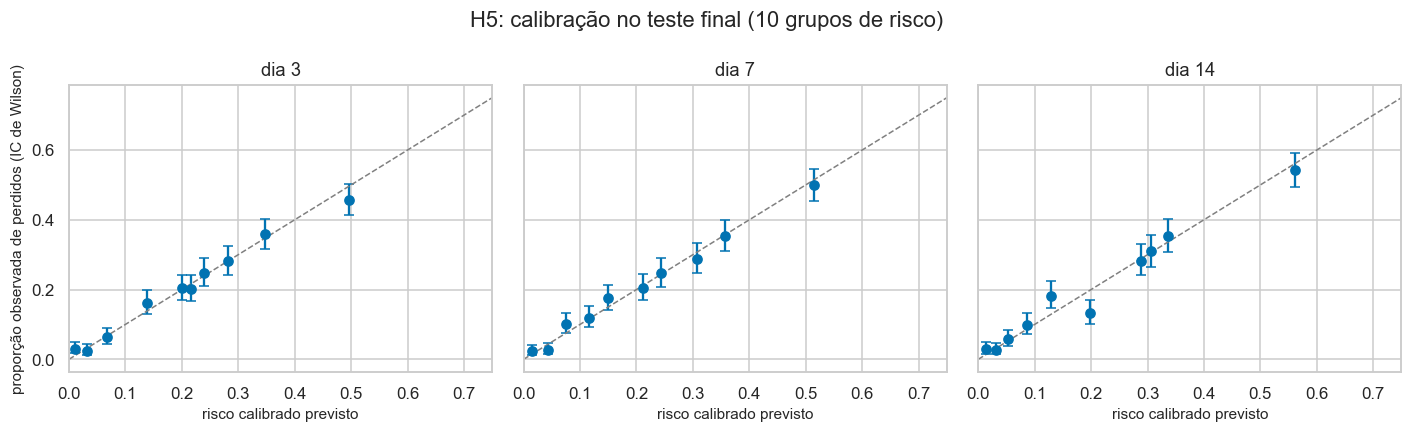

In [8]:
def hl(y, p, g=10):
    t = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)}); t["g"] = pd.qcut(t.p.rank(method="first"), g, labels=False)
    r = t.groupby("g").agg(n=("y", "size"), esperado=("p", "sum"), observado=("y", "sum"), p=("p", "mean"))
    est = float((((r.observado - r.esperado) ** 2) / (r.esperado * (1 - r.p))).sum()); return est, float(chi2.sf(est, g - 2)), r

linhas, GRP = [], {}
for d in CK:
    y = A[d]["y"]
    for nome, p in (("bruto", A[d]["p"]), ("calibrado", A[d]["pc"])):
        est, pv, r = hl(y, p); GRP[(d, nome)] = r
        linhas.append({"dia": d, "risco": nome, "estatística HL": est, "p": pv, "decisão (α = 0,05)": "rejeita H0 (descalibrado)" if pv < ALPHA else "não rejeita H0"})
        if nome == "calibrado": reg(f"H5 dia {d}", "esperado não rejeitar", "risco calibrado = proporção observada", "Hosmer-Lemeshow", f"estatística {est:.1f} (8 g.l.)", pv)
th = pd.DataFrame(linhas); display(th.round(4))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, d in zip(axes, CK):
    r = GRP[(d, "calibrado")]; obs = r.observado / r.n; lo = [binomtest(int(o), int(n)).proportion_ci(method="wilson").low for o, n in zip(r.observado, r.n)]; hi = [binomtest(int(o), int(n)).proportion_ci(method="wilson").high for o, n in zip(r.observado, r.n)]
    ax.errorbar(r.p, obs, yerr=[obs - np.array(lo), np.array(hi) - obs], fmt="o", capsize=3); ax.plot([0, .75], [0, .75], "--", color="gray", lw=1); ax.set_title(f"dia {d}"); ax.set_xlabel("risco calibrado previsto"); ax.set_xlim(0, .75)
axes[0].set_ylabel("proporção observada de perdidos (IC de Wilson)"); fig.suptitle("H5: calibração no teste final (10 grupos de risco)"); plt.tight_layout(); plt.show()

# 8. H6: a lista de risco alto concentra mesmo as perdas?

**H0:** a taxa de perda entre os onboardings sinalizados é igual à taxa base do teste final. **H1:** é maior.
Dois recortes: (a) risco calibrado **>= 35%**, a regra recomendada; (b) os **20% de maior risco**. Teste binomial de um lado contra a taxa base, IC de Wilson e IC por bootstrap de clientes para a precisão.

In [9]:
linhas = []
for d in CK:
    a = A[d]; y = a["y"]; base = y.mean(); n_tot = len(y)
    ordem = np.lexsort((np.random.default_rng(0).random(n_tot), -a["p"]))[: int(round(0.2 * n_tot))]
    for nome, sel in (("risco calibrado >= 35%", np.flatnonzero(a["pc"] >= 0.35)), ("20% de maior risco", ordem)):
        k, n = int(y[sel].sum()), len(sel); bt = binomtest(k, n, base, alternative="greater"); w = binomtest(k, n).proportion_ci(method="wilson")
        marc = np.zeros(n_tot, bool); marc[sel] = True
        prec = boot(d, lambda i: y[i][marc[i]].mean() if marc[i].any() else np.nan); lo, hi = np.nanpercentile(prec, [2.5, 97.5])
        linhas.append({"dia": d, "recorte": nome, "sinalizados": n, "perdidos": k, "precisão": k / n, "taxa base": base, "IC Wilson": f"{w.low:.3f} a {w.high:.3f}", "IC por cliente": f"{lo:.3f} a {hi:.3f}", "captura das perdas": k / y.sum(), "p": bt.pvalue})
        reg(f"H6 dia {d} ({nome})", "esperado rejeitar", "precisão > taxa base", "binomial (um lado)", f"precisão {k / n:.1%} vs base {base:.1%} (Wilson {w.low:.1%} a {w.high:.1%})", bt.pvalue)
t6 = pd.DataFrame(linhas); display(t6.assign(p=t6.p.map(fmtp)).round(3))
assert (t6.p.astype(float) < 0.001).all() and (t6.precisão > 1.9 * t6["taxa base"]).all()
print("Conclusão H6: a lista concentra as perdas: a precisão é pelo menos o dobro da taxa base em todos os recortes, com IC bem acima da taxa base.")

,dia,recorte,sinalizados,perdidos,precisão,taxa base,IC Wilson,IC por cliente,captura das perdas,p
0,3,risco calibrado >= 35%,612,270,0.441,0.203,0.402 a 0.481,0.372 a 0.515,0.294,2.3e-40
1,3,20% de maior risco,904,376,0.416,0.203,0.384 a 0.448,0.359 a 0.477,0.410,5.3e-48
2,7,risco calibrado >= 35%,755,322,0.426,0.204,0.392 a 0.462,0.366 a 0.490,0.368,1.2e-43
3,7,20% de maior risco,860,359,0.417,0.204,0.385 a 0.451,0.361 a 0.477,0.410,6.4e-46
4,14,risco calibrado >= 35%,425,221,0.520,0.201,0.473 a 0.567,0.455 a 0.591,0.285,6.1e-48
5,14,20% de maior risco,769,340,0.442,0.201,0.407 a 0.477,0.386 a 0.503,0.439,2.4e-51


Conclusão H6: a lista concentra as perdas: a precisão é pelo menos o dobro da taxa base em todos os recortes, com IC bem acima da taxa base.


# 9. H7: o desempenho se mantém ao longo do tempo?

Dividimos o teste final por trimestre de criação. **H0:** o AUC do primeiro trimestre completo é igual ao do último. **H1:** são diferentes (dois lados). Aqui, **não rejeitar** é o resultado desejado; um valor p pequeno indicaria deriva (o modelo envelhecendo). O poder do teste é limitado em trimestres pequenos, então o IC de cada trimestre também conta.

dia,3,7,14
trimestre,,,
2025Q1,0.745,0.742,0.757
2025Q2,0.723,0.739,0.798
2025Q3,0.785,0.763,0.795
2025Q4,0.692,0.730,0.721
2026Q1,0.748,0.767,0.807
2026Q2,0.758,0.767,0.790


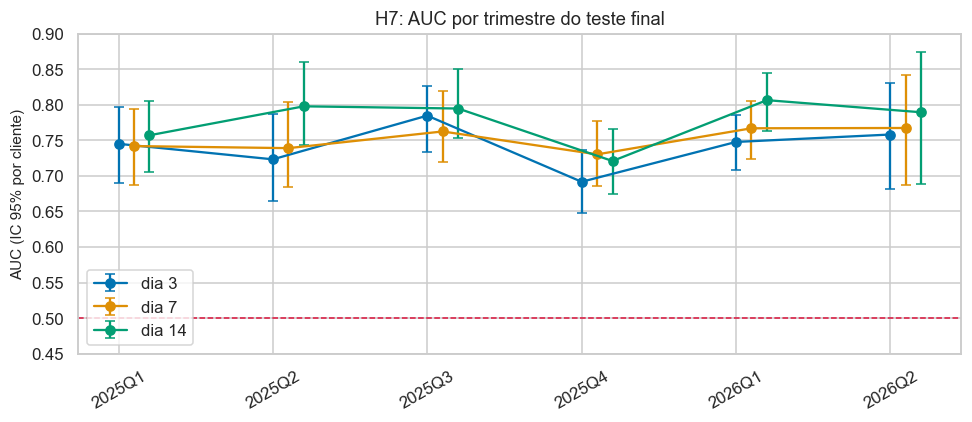

       id                               medida     p
 H7 dia 3 diferença -0.013 (IC -0.107 a 0.083) 0.825
 H7 dia 7 diferença -0.025 (IC -0.119 a 0.072) 0.622
H7 dia 14 diferença -0.032 (IC -0.132 a 0.081) 0.566


In [10]:
linhas, Q = [], {}
for d in CK:
    a = A[d]; y, p = a["y"], a["p"]; q = pd.to_datetime(a["ho"].created_at).dt.to_period("Q").astype(str).values; a["q"] = q
    qs = [k for k in sorted(set(q)) if (q == k).sum() >= 300]; Q[d] = qs
    for k in qs:
        m = q == k; bs = np.array([auc_fast(y[i[q[i] == k]], p[i[q[i] == k]]) for i in (idx(d, b) for b in range(B_REP))]); a.setdefault("qboot", {})[k] = bs
        linhas.append({"dia": d, "trimestre": k, "n": int(m.sum()), "perdidos": int(y[m].sum()), "AUC": auc_fast(y[m], p[m]), "IC 95%": f"{ic(bs)[0]:.3f} a {ic(bs)[1]:.3f}"})
    dif = a["qboot"][qs[0]] - a["qboot"][qs[-1]]; pt = auc_fast(y[q == qs[0]], p[q == qs[0]]) - auc_fast(y[q == qs[-1]], p[q == qs[-1]]); pv = p_dois_lados(dif)
    reg(f"H7 dia {d}", "esperado não rejeitar", f"AUC {qs[0]} = AUC {qs[-1]}", "bootstrap por cliente (dois lados)", f"diferença {pt:+.3f} (IC {ic(dif)[0]:.3f} a {ic(dif)[1]:.3f})", pv)
t7 = pd.DataFrame(linhas); display(t7.pivot(index="trimestre", columns="dia", values="AUC").round(3))

fig, ax = plt.subplots(figsize=(9, 4)); cores = sns.color_palette("colorblind")
for j, d in enumerate(CK):
    qs = Q[d]; mu = [auc_fast(A[d]["y"][A[d]["q"] == k], A[d]["p"][A[d]["q"] == k]) for k in qs]; lo = [ic(A[d]["qboot"][k])[0] for k in qs]; hi = [ic(A[d]["qboot"][k])[1] for k in qs]
    ax.errorbar(np.arange(len(qs)) + 0.1 * j, mu, yerr=[np.array(mu) - lo, np.array(hi) - np.array(mu)], fmt="o-", capsize=3, color=cores[j], label=f"dia {d}")
ax.axhline(0.5, color="crimson", ls="--", lw=1); ax.set_xticks(range(len(Q[3]))); ax.set_xticklabels(Q[3], rotation=30); ax.set_ylabel("AUC (IC 95% por cliente)"); ax.set_ylim(0.45, 0.9); ax.legend(); ax.set_title("H7: AUC por trimestre do teste final"); plt.tight_layout(); plt.show()
print(pd.DataFrame([r for r in RES if r["id"].startswith("H7")])[["id", "medida", "p"]].round(3).to_string(index=False))

# 10. H8: os sinais e o vazamento são reais?

Testes simples e diretos das afirmações da análise descritiva e da modelagem. Cada linha compara a taxa de perda (ou a distribuição) com e sem o sinal.

* **Login** até o dia 3 e **contrato assinado** até o dia 14: tabelas 2 x 2, qui-quadrado e razão de chances (OR) com IC de Woolf. OR > 1 significa mais perdas **sem** o sinal.
* **Parcela de tarefas concluídas até o dia 7** e **histórico de perdas do cliente**: Mann-Whitney (probabilidade de superioridade).
* **País**: qui-quadrado de independência (países com menos de 100 onboardings agrupados) e V de Cramér.
* **Vazamento (plano A):** o campo *tipo de emprego* em branco no dia 0 vs preenchido. É o argumento para excluir os campos preenchidos durante o onboarding.

In [11]:
def or_ic(a, b, c, d_):   # a = perdidos sem sinal, b = concluídos sem sinal, c = perdidos com sinal, d_ = concluídos com sinal
    o = (a * d_) / (b * c); se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d_); return o, np.exp(np.log(o) - 1.96 * se), np.exp(np.log(o) + 1.96 * se)

linhas = []
def dois_por_dois(nome, pop, sem_sinal, hip):
    s = sem_sinal.values; y = pop.y_lost.values
    a, b, c, d_ = int(y[s].sum()), int((1 - y[s]).sum()), int(y[~s].sum()), int((1 - y[~s]).sum())
    chi = chi2_contingency([[a, b], [c, d_]], correction=False); o, lo, hi = or_ic(a, b, c, d_)
    linhas.append({"sinal": nome, "n sem sinal": a + b, "% perdidos sem sinal": a / (a + b), "n com sinal": c + d_, "% perdidos com sinal": c / (c + d_), "OR": o, "IC 95% da OR": f"{lo:.1f} a {hi:.1f}", "p (qui-quadrado)": chi[1]})
    reg(f"H8 {nome}", "esperado rejeitar", hip, "qui-quadrado 2x2", f"{a / (a + b):.1%} vs {c / (c + d_):.1%} perdidos; OR {o:.1f} ({lo:.1f} a {hi:.1f})", chi[1])

pop3 = pd.concat([A[3]["tr"], A[3]["ho"]], ignore_index=True); pop14 = pd.concat([A[14]["tr"], A[14]["ho"]], ignore_index=True)
dois_por_dois("sem login até o dia 3", pop3, pop3.login_d3.fillna(0) == 0, "perda independe do login até o dia 3")
dois_por_dois("contrato não assinado até o dia 14", pop14, pop14.done_employee_contract_sign_d14.fillna(0) == 0, "perda independe de contrato assinado até o dia 14")
extra = pd.read_csv(INPUT / "onboardings_day0.csv", low_memory=False, usecols=["onboarding_id", "employment_type"]); dv = df.merge(extra, on="onboarding_id", how="left")
dois_por_dois("tipo de emprego em branco no dia 0", dv, dv.employment_type.isna() | (dv.employment_type.astype(str).str.strip() == ""), "perda independe de o tipo de emprego estar em branco")
t8 = pd.DataFrame(linhas); display(t8.assign(**{"p (qui-quadrado)": t8["p (qui-quadrado)"].map(fmtp)}).round(3))
assert t8["OR"].gt(2).all() and (t8["% perdidos sem sinal"] > t8["% perdidos com sinal"]).all()
vz = t8[t8.sinal.str.startswith("tipo")].iloc[0]; assert 0.30 < vz["% perdidos sem sinal"] < 0.38 and 0.02 < vz["% perdidos com sinal"] < 0.06
print("OK: o campo em branco no dia 0 vem com 34% de perdas contra 4% quando preenchido (documentado: 34% vs 4%).")

def mw(nome, pop, col, hip, alt):
    x = pop[["y_lost", col]].dropna(); a, b = x[x.y_lost == 1][col].values, x[x.y_lost == 0][col].values
    r = mannwhitneyu(a, b, alternative=alt); ps = r.statistic / (len(a) * len(b))
    reg(f"H8 {nome}", "esperado rejeitar", hip, "Mann-Whitney (um lado)", f"mediana perdidos {np.median(a):.2f} vs concluídos {np.median(b):.2f}; prob. de superioridade {ps:.2f}", r.pvalue)
    return {"variável": nome, "mediana perdidos": np.median(a), "mediana concluídos": np.median(b), "prob. de superioridade (perdidos > concluídos)": ps, "p": r.pvalue}
m1 = mw("parcela de tarefas concluídas (dia 7)", pd.concat([A[7]["tr"], A[7]["ho"]]), "tasks_done_share_d7", "perdidos têm parcela menor", "less")
m2 = mw("histórico de perdas do cliente", df[df.client_prior_resolved > 0], "client_prior_lost_rate", "perdidos vêm de clientes com taxa anterior maior", "greater")
display(pd.DataFrame([m1, m2]).assign(p=lambda t: t.p.map(fmtp)).round(3))

ct = pd.crosstab(df.country.where(df.country.map(df.country.value_counts()) >= 100, "outros"), df.y_lost); chi = chi2_contingency(ct); V = np.sqrt(chi[0] / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"país: {ct.shape[0]} grupos, qui-quadrado {chi[0]:.0f} ({chi[2]} g.l.), p = {chi[1]:.1e}, V de Cramér = {V:.2f}")
reg("H8 país", "esperado rejeitar", "perda independe do país", "qui-quadrado de independência", f"V de Cramér {V:.2f} ({ct.shape[0]} grupos)", chi[1])

,sinal,n sem sinal,% perdidos sem sinal,n com sinal,% perdidos com sinal,OR,IC 95% da OR,p (qui-quadrado)
0,sem login até o dia 3,9554,0.213,957,0.103,2.350,1.9 a 2.9,8.2e-16
1,contrato não assinado até o dia 14,7741,0.239,1404,0.022,13.919,9.7 a 19.9,1.8e-76
2,tipo de emprego em branco no dia 0,9592,0.336,10263,0.042,11.455,10.3 a 12.7,< 1e-300


OK: o campo em branco no dia 0 vem com 34% de perdas contra 4% quando preenchido (documentado: 34% vs 4%).


,variável,mediana perdidos,mediana concluídos,prob. de superioridade (perdidos > concluídos),p
0,parcela de tarefas concluídas (dia 7),0.125,0.190,0.372,1.6e-73
1,histórico de perdas do cliente,0.162,0.149,0.558,6.1e-20


país: 49 grupos, qui-quadrado 771 (48 g.l.), p = 3.8e-131, V de Cramér = 0.20


# 11. H9: o resultado vem de vazamento ou de erro no código?

Teste de **permutação dos rótulos**. Embaralhamos os rótulos do treino (quebrando qualquer relação real entre atributos e desfecho), treinamos o mesmo modelo e medimos o AUC no teste final. Se o pipeline estiver limpo, os AUCs embaralhados ficam em torno de 0,5; se algum atributo "soubesse" a resposta (vazamento de futuro, por exemplo), o AUC sobreviveria ao embaralhamento. **H0:** o AUC real é o que se espera com rótulos sem informação. Com 20 permutações o menor valor p possível é 1/21 (cerca de 0,048): é uma verificação de sanidade, não um teste de alta resolução.

,dia,AUC real,AUC embaralhado: média,mínimo,máximo,p (permutação)
0,3,0.741,0.493,0.433,0.523,0.048
1,7,0.750,0.500,0.457,0.544,0.048
2,14,0.777,0.504,0.439,0.565,0.048


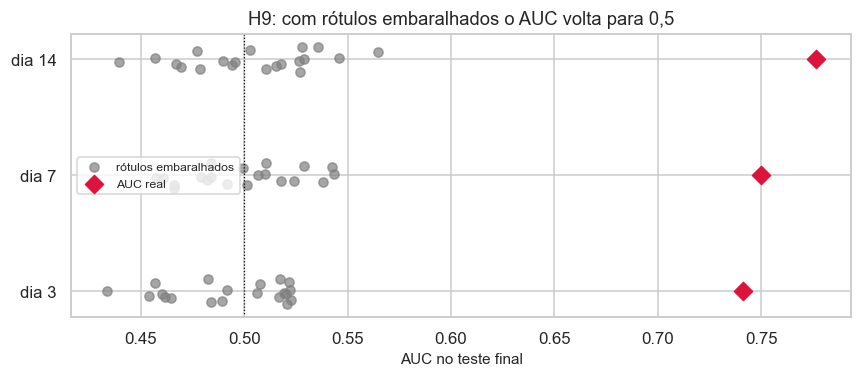

In [12]:
NPERM, linhas, NULL = 20, [], {}
for d in CK:
    a = A[d]; tr, ho = a["tr"], a["ho"]; rp = np.random.default_rng(100 + d); vals = []
    for _ in range(NPERM):
        yp = rp.permutation(tr.y_lost.values); vals.append(auc_fast(a["y"], MU.predict_raw(MU.fit(tr, a["cols"], yp, seeds=(0,)), ho)))
    NULL[d] = np.array(vals); real = auc_fast(a["y"], a["p"]); pv = (1 + np.sum(NULL[d] >= real)) / (NPERM + 1)
    linhas.append({"dia": d, "AUC real": real, "AUC embaralhado: média": NULL[d].mean(), "mínimo": NULL[d].min(), "máximo": NULL[d].max(), "p (permutação)": pv})
    reg(f"H9 dia {d}", "verificação de sanidade", "AUC real = AUC com rótulos embaralhados", "permutação (20)", f"real {real:.3f} vs embaralhado {NULL[d].mean():.3f} (máx {NULL[d].max():.3f})", pv)
t9 = pd.DataFrame(linhas); display(t9.round(3))
assert (t9["AUC embaralhado: média"].between(0.46, 0.54)).all() and (t9["máximo"] < 0.60).all() and (t9["AUC real"] > t9["máximo"] + 0.15).all()

fig, ax = plt.subplots(figsize=(8, 3.6))
for j, d in enumerate(CK):
    ax.scatter(NULL[d], np.full(NPERM, j) + np.random.default_rng(1).uniform(-.12, .12, NPERM), color="gray", alpha=.7, label="rótulos embaralhados" if j == 0 else None)
    ax.scatter([auc_fast(A[d]["y"], A[d]["p"])], [j], color="crimson", s=70, marker="D", label="AUC real" if j == 0 else None)
ax.set_yticks(range(3)); ax.set_yticklabels([f"dia {d}" for d in CK]); ax.axvline(0.5, color="black", lw=.8, ls=":"); ax.set_xlabel("AUC no teste final"); ax.legend(loc="center left", fontsize=8); ax.set_title("H9: com rótulos embaralhados o AUC volta para 0,5"); plt.tight_layout(); plt.show()

# 12. H10: as "razões" do alerta fazem sentido?

O alerta mostra razões como "contrato não assinado (-X pontos se corrigido)". Isso supõe que o modelo **reduz o risco** quando o sinal é corrigido. **H0:** o risco previsto não muda ao corrigir o sinal. **H1:** o risco cai. Para os onboardings do teste final sem o sinal (contrato não assinado; sem login), trocamos o sinal pelo valor "em dia" e comparamos o risco antes e depois com o teste de **Wilcoxon pareado** (um lado). Isto valida o comportamento do modelo, **não** que corrigir o sinal na vida real evitaria a perda: as razões são associações, não causas.

In [13]:
linhas = []
for d, col, nome in ((7, "done_employee_contract_sign_d7", "contrato não assinado (dia 7)"), (14, "done_employee_contract_sign_d14", "contrato não assinado (dia 14)"), (7, "login_d7", "sem login (dia 7)")):
    a = A[d]; G = a["ho"][a["ho"][col].fillna(0) == 0].copy(); antes = MU.predict_raw(a["b"], G); H = G.copy(); H[col] = 1; depois = MU.predict_raw(a["b"], H)
    w = wilcoxon(antes - depois, alternative="greater")
    linhas.append({"correção": nome, "onboardings": len(G), "risco médio antes": antes.mean(), "risco médio depois": depois.mean(), "queda mediana (pontos)": 100 * np.median(antes - depois), "% com queda": np.mean(antes > depois), "p (Wilcoxon)": w.pvalue})
    reg(f"H10 {nome}", "esperado rejeitar", "risco cai ao corrigir o sinal", "Wilcoxon pareado (um lado)", f"queda mediana {100 * np.median(antes - depois):.1f} pontos; {np.mean(antes > depois):.0%} dos casos caem", w.pvalue)
t10 = pd.DataFrame(linhas); display(t10.assign(**{"p (Wilcoxon)": t10["p (Wilcoxon)"].map(fmtp)}).round(3))
assert (t10["queda mediana (pontos)"] > 0).all() and (t10["% com queda"] > 0.6).all()

,correção,onboardings,risco médio antes,risco médio depois,queda mediana (pontos),% com queda,p (Wilcoxon)
0,contrato não assinado (dia 7),3501,0.190,0.074,10.672,1.000,< 1e-300
1,contrato não assinado (dia 14),2923,0.203,0.064,12.679,1.000,< 1e-300
2,sem login (dia 7),3056,0.201,0.098,9.626,0.992,< 1e-300


# 13. Resumo: todas as hipóteses, com correção de Holm

In [14]:
R = pd.DataFrame(RES)
fam = R.familia == "esperado rejeitar"; ordem = R[fam].p.sort_values().index; m = fam.sum(); aj = {}; corrente = 0.0
for k, i in enumerate(ordem):              # Holm: p ajustado = max até agora de (m - k) * p, limitado a 1
    corrente = max(corrente, min(1.0, (m - k) * R.loc[i, "p"])); aj[i] = corrente
R["p ajustado (Holm)"] = pd.Series(aj); R.loc[~fam, "p ajustado (Holm)"] = np.nan
san = R.familia == "verificação de sanidade"
R["decisão (α = 0,05)"] = np.where(fam, np.where(R["p ajustado (Holm)"] < ALPHA, "rejeita H0: efeito confirmado", "não rejeita H0: sem evidência"), np.where(san, "AUC real acima de todas as permutações", np.where(R.p >= ALPHA, "não rejeita H0: sem sinal de problema", "rejeita H0: sinal de problema")))
resumo = R[["id", "hipotese", "medida", "p", "p ajustado (Holm)", "decisão (α = 0,05)"]].rename(columns={"hipotese": "hipótese (H1)", "p": "p (sem correção)"})
with pd.option_context("display.max_colwidth", 90, "display.width", 260):
    display(resumo.assign(**{"p (sem correção)": resumo["p (sem correção)"].map(fmtp), "p ajustado (Holm)": resumo["p ajustado (Holm)"].map(lambda v: "" if pd.isna(v) else fmtp(v))}))
print(f"{m} testes na família de Holm; {int((R[fam]['p ajustado (Holm)'] < ALPHA).sum())} confirmam o efeito esperado.")
print("tempo total do caderno:", round(time.time() - T0), "s")

,id,hipótese (H1),medida,p (sem correção),p ajustado (Holm),"decisão (α = 0,05)"
0,H1 dia 3,"AUC > 0,5",AUC 0.741 (IC 0.715 a 0.767),5.0e-04,5.0e-03,rejeita H0: efeito confirmado
1,H1 dia 7,"AUC > 0,5",AUC 0.750 (IC 0.724 a 0.777),5.0e-04,5.0e-03,rejeita H0: efeito confirmado
2,H1 dia 14,"AUC > 0,5",AUC 0.777 (IC 0.750 a 0.803),5.0e-04,5.0e-03,rejeita H0: efeito confirmado
3,H2 dia 3,modelo - histórico do cliente > 0,diferença de AUC +0.158 (IC 0.129 a 0.190),5.0e-04,5.0e-03,rejeita H0: efeito confirmado
4,H3 dia 3,modelo completo - modelo só dia 0 > 0,diferença de AUC +0.144 (IC 0.125 a 0.163),5.0e-04,5.0e-03,rejeita H0: efeito confirmado
5,H2 dia 7,modelo - histórico do cliente > 0,diferença de AUC +0.173 (IC 0.142 a 0.208),5.0e-04,5.0e-03,rejeita H0: efeito confirmado
6,H3 dia 7,modelo completo - modelo só dia 0 > 0,diferença de AUC +0.144 (IC 0.123 a 0.166),5.0e-04,5.0e-03,rejeita H0: efeito confirmado
7,H2 dia 14,modelo - histórico do cliente > 0,diferença de AUC +0.197 (IC 0.163 a 0.234),5.0e-04,5.0e-03,rejeita H0: efeito confirmado
8,H3 dia 14,modelo completo - modelo só dia 0 > 0,diferença de AUC +0.172 (IC 0.144 a 0.199),5.0e-04,5.0e-03,rejeita H0: efeito confirmado
9,H4 dia 14 vs 3,AUC dia 14 > AUC dia 3,diferença de AUC +0.035 (IC 0.017 a 0.055),1.0e-03,5.0e-03,rejeita H0: efeito confirmado


25 testes na família de Holm; 25 confirmam o efeito esperado.
tempo total do caderno: 32 s


# 14. Conclusão: o que os testes validam e o que não validam

**O que os testes validam** (todos com semente fixa, intervalos por cliente e correção de Holm onde se espera um efeito):

| Suposição | Resultado |
|---|---|
| O modelo separa perdidos de concluídos (H1) | **Sim.** AUC 0,741 / 0,750 / 0,777 nos dias 3, 7 e 14, com IC 95% de cerca de ±0,026; nenhum dos 2.000 sorteios de clientes chega a 0,5. |
| O modelo vale mais que regras simples (H2, H3) | **Sim.** Ganha 0,16 a 0,20 de AUC do "histórico do cliente" (AUC cerca de 0,58) e 0,14 a 0,17 do modelo só com atributos do dia 0 (cerca de 0,60). Os eventos do onboarding são o que carrega o sinal. |
| Mais dias, melhor modelo (H4) | **Em parte.** O dia 14 é melhor que o dia 3 (+0,035; IC 0,017 a 0,055). Entre o dia 3 e o dia 7 não há diferença detectável (+0,009; p = 0,25). |
| A lista de risco alto concentra perdas (H6) | **Sim.** Risco calibrado >= 35%: precisão de 44% / 43% / 52% contra uma taxa base de cerca de 20%; os 20% de maior risco têm 42% / 42% / 44%. Todos os IC ficam bem acima da taxa base. |
| Os sinais e o vazamento são reais (H8) | **Sim.** Tipo de emprego em branco no dia 0: 34% de perdas contra 4% (OR 11): justifica o plano A. Contrato não assinado até o dia 14: 24% contra 2% (OR 14). Sem login até o dia 3: 21% contra 10% (OR 2,4; mas só cerca de 9% dos onboardings têm login registrado nessa data, então o sinal deve ser lido com cuidado). O histórico de perdas do cliente é significativo mas **fraco** (probabilidade de superioridade 0,56). País importa de forma moderada (V de Cramér 0,20). |
| Não há vazamento nem erro no código (H9) | **Nenhum sinal de problema.** Com rótulos embaralhados o AUC volta a 0,49 a 0,50 (máximo 0,565); o AUC real, 0,74 a 0,78, fica acima de todas as 20 permutações. |
| As razões do alerta fazem sentido (H10) | **Sim, como comportamento do modelo.** Corrigir "contrato não assinado" ou "sem login" reduz o risco em 99% a 100% dos casos (queda mediana de 10 a 13 pontos). |

**O que os testes não validam, ou validam só em parte.**

* **Calibração (H5).** O risco calibrado só passa no teste de Hosmer-Lemeshow no dia 7 (p = 0,20); no dia 3 (p = 0,014) e no dia 14 (p < 0,001) o teste rejeita H0. O erro de calibração é pequeno (1 a 2 pontos, caderno 2), e com mais de 3.800 linhas o teste detecta desvios pequenos, mas a frase "risco de 35% = 35 em 100" é **aproximada**, não exata. A calibração deve ser refeita a cada nova rodada de treino.
* **Estabilidade no tempo (H7).** Não há sinal de deriva (diferenças de AUC entre o primeiro e o último trimestre de -0,03 a -0,01, p entre 0,57 e 0,83), mas os IC são largos (de cerca de -0,13 a +0,08): o teste tem pouco poder com 600 a 1.000 linhas por trimestre. "Não rejeitar" não prova estabilidade. O trimestre mais fraco foi 2025Q4 no dia 3 (AUC 0,69).
* **Tamanho do efeito.** Os valores p são minúsculos porque o teste final é grande; o que importa é o tamanho do efeito: AUC de 0,74 a 0,78 é **moderado**. Separa bem em média, mas a precisão da lista é de 43% a 52%: cerca de metade dos alertas não vira perda.
* **Fora do alcance destes testes:** (i) se agir sobre os alertas **evita** perdas (as razões são associações; só um piloto com grupo de comparação responde); (ii) o `pending_deposit`, que não existia nos dados de treino; (iii) períodos futuros além de uma única divisão temporal (treino antes de 2025, teste de 2025 a 2026-06); (iv) a calibração e o teste usam o mesmo conjunto de teste final (com validação cruzada por semana), então os números de calibração podem estar levemente otimistas.

**Como repetir.** Execute os cadernos nesta ordem: 1, 2, 3 (o 3 usa a base final do 1 e `src/`; não lê os modelos salvos para avaliar, só para demonstrar o uso). Tempo: cerca de 35 segundos.